In [1]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

Импортированы необходимые зависимости

Загрузка и очистка данных

In [2]:
df = pd.read_csv('creditcard.csv')

class_counts = df['Class'].value_counts(normalize=True)*100
print(f'Баланс классов: \nБезопасная транзакция - {class_counts[0]:.1f}%\nМошенническая транзакция - {class_counts[1]:.1f}%')
x = df.drop('Class', axis = 1)
y = df['Class']

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(df.columns)

Баланс классов: 
Безопасная транзакция - 99.8%
Мошенническая транзакция - 0.2%
Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')


Данные загружеы, получена информация о распределении классов транзакций. Данные разделены на train и test

Предобработка

In [8]:
numeric_features = ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

numeric_transformer = Pipeline(
    steps=[('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
    ]
)

clf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier())
    ]
)

param_grid = {
    'classifier__n_neighbors': [3, 5, 9],
    'classifier__weights': ['uniform', 'distance']
}

cv_strategy = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=clf_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(xtrain, ytrain)
best_model = grid_search.best_estimator_
print(f'Лучшие параметры алгоритма: {grid_search.best_params_}')

Лучшие параметры алгоритма: {'classifier__n_neighbors': 9, 'classifier__weights': 'distance'}


Произведён перебор параметров модели для работы с подготовленными данными, получены наиболее оптимальные параметры модели

In [9]:
ypred = best_model.predict(xtest)
yproba = best_model.predict_proba(xtest)[:,1]

print('---Матрица ошибок---')
conf_matrix = confusion_matrix(ytest, ypred)
print(f'Истинно отрицательные (TN - не мошенник, предсказано верно) {conf_matrix[0][0]}')
print(f'Ложноположительные (FP - не мошенник, предсказано неверно) {conf_matrix[0][1]}')
print(f'Ложноотрицательные (FN - мошенник, предсказано неверно) {conf_matrix[1][0]}')
print(f'Истинно положительные (TP - мошенник, предсказано верно) {conf_matrix[1][1]}')

print('---Отчёт по метрикам---')
print(classification_report(ytest, ypred, target_names=['Не мошенник (0)', 'Мошенник (1)']))

roc_auc = roc_auc_score(ytest, yproba)
print(f'Площадь под кривой ROC-AUC: {roc_auc:.4f}')

---Матрица ошибок---
Истинно отрицательные (TN - не мошенник, предсказано верно) 56859
Ложноположительные (FP - не мошенник, предсказано неверно) 5
Ложноотрицательные (FN - мошенник, предсказано неверно) 23
Истинно положительные (TP - мошенник, предсказано верно) 75
---Отчёт по метрикам---
                 precision    recall  f1-score   support

Не мошенник (0)       1.00      1.00      1.00     56864
   Мошенник (1)       0.94      0.77      0.84        98

       accuracy                           1.00     56962
      macro avg       0.97      0.88      0.92     56962
   weighted avg       1.00      1.00      1.00     56962

Площадь под кривой ROC-AUC: 0.9488


Построена матрица ошибок, по которой видно, что модель редко ошибается, при этом опасность заключается в том, что ложноотрицательный прогноз встречается чаще, чем ложноположительный, т.е. модель склонна счиать транзакцию легитимной, тогда как для банка лучше заблокировать транзакцию, нежели допустить мошенническую.

In [10]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

Дополнительные импорты произведены

Регрессия

In [15]:
df_reg = df.dropna(subset=['Class']).copy()
xreg = df_reg[['Amount', 'Time']]
yreg = df_reg['Class']

xtrainr, xtestr, ytrainr, ytestr = train_test_split(xreg, yreg, test_size=0.2, random_state=42)

reg_pipeline = Pipeline(
    [('scaler', StandardScaler()), ('knn_reg', KNeighborsRegressor())]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    'knn_reg__n_neighbors': np.arange(3, 30),
    'knn_reg__weights': ['uniform', 'distance']
}

random_search = RandomizedSearchCV(
    estimator=reg_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(xtrainr, ytrainr)
best_reg = random_search.best_estimator_
print(f'Лучшие параметры алгоритма: {random_search.best_params_}')

Лучшие параметры алгоритма: {'knn_reg__weights': 'distance', 'knn_reg__n_neighbors': np.int64(4)}


Были вычислены лучшие параметры регрессионного алгоритма

In [16]:
ypredr = best_reg.predict(xtestr)
def smape(ytest, ypred):
    return 100 * np.mean(
        2 * np.abs(ypred - ytest) / (np.abs(ytest) + np.abs(ypred))
    )
mse = mean_squared_error(ytestr, ypredr)
rmse = np.sqrt(mse)
mae = mean_absolute_error(ytestr, ypredr)
smape_value = smape(ytestr, ypredr)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE: {mse:.0f}")
print(f"RMSE: {rmse:.0f}")
print(f"MAE (Средняя ошибка): {mae:.2f}")
print(f"SMAPE (ошибка в %): {smape_value:.2f}%")

--- Отчет по метрикам регрессии ---
MSE: 0
RMSE: 0
MAE (Средняя ошибка): 0.00
SMAPE (ошибка в %): 194.86%


Серьёзные ошибки показала только метрика SMAPE

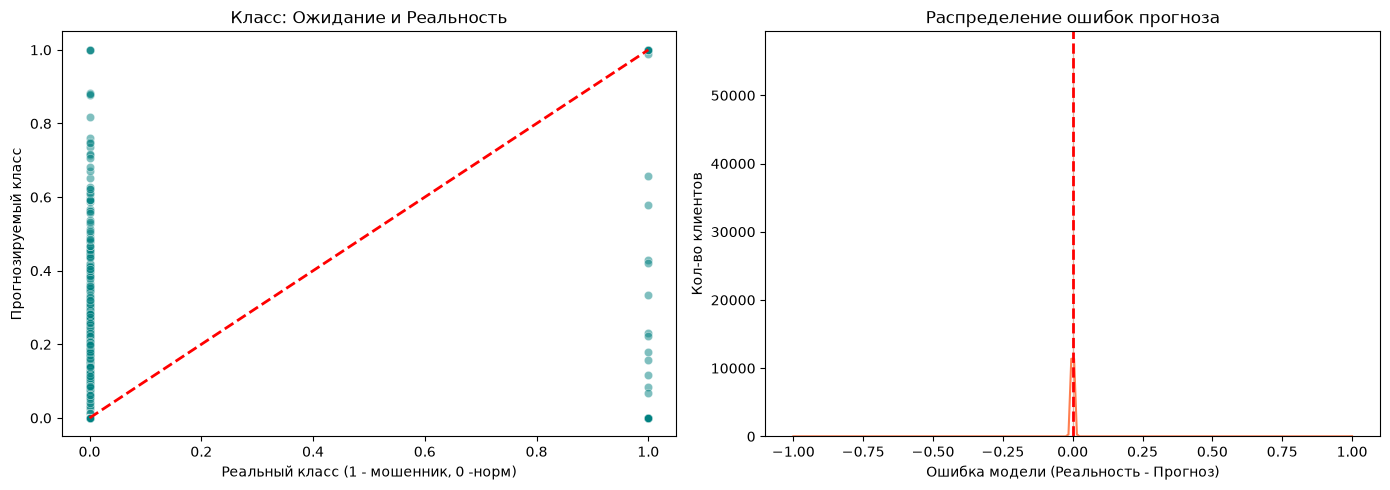

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1 график: Факт vs Прогноз
sns.scatterplot(x=ytestr, y=ypredr, alpha=0.5, color="teal", ax=axes[0])
ymin = min(ytestr.min(), ypredr.min())
ymax = max(ytestr.max(), ypredr.max())
axes[0].plot([ymin, ymax], [ymin, ymax], 'r--', lw=2)
axes[0].set_title("Класс: Ожидание и Реальность")
axes[0].set_xlabel("Реальный класс (1 - мошенник, 0 -норм)")
axes[0].set_ylabel("Прогнозируемый класс")

# 2 график: Распределение ошибок
residuals = ytestr - ypredr
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--', lw=2)
axes[1].set_title("Распределение ошибок прогноза")
axes[1].set_xlabel("Ошибка модели (Реальность - Прогноз)")
axes[1].set_ylabel("Кол-во клиентов")

plt.tight_layout()
plt.show()

Несмотря на то, что метрики точности показывают, что модель получилась весьма точной, графики это не отражают, потому что они не оптимизированы для отображения бинарных данных (0 - нормальная транзакция, 1 - мошенническая). Поэтому прогнозируемые классы оказываются дробными, однако видно, что большинство транзакций класса 0 получили прогноз менее 0.5, т.е. модель присвоила бы им класс 0, что верно. Видно скопление точек, класс которых и на прогнозе, и в реальности - 1 (однако наблюдаются и выбросы, когда модель не распознала мошенническую транзакцию и допустила её). Однако в целом точность модели весьма высокая.